Period T = 86.910000 days
Integrating adjoint for 50 periods (4345.5 days)
omega = 2*pi/T = 0.072295
Z . gamma' after normalization: 0.072295 to 0.072295
Z_S range: [-3.3699, 14.5926]
Z_I range: [-63.3825, 227.6988]
Z_v range: [-1.2426, 0.9757]


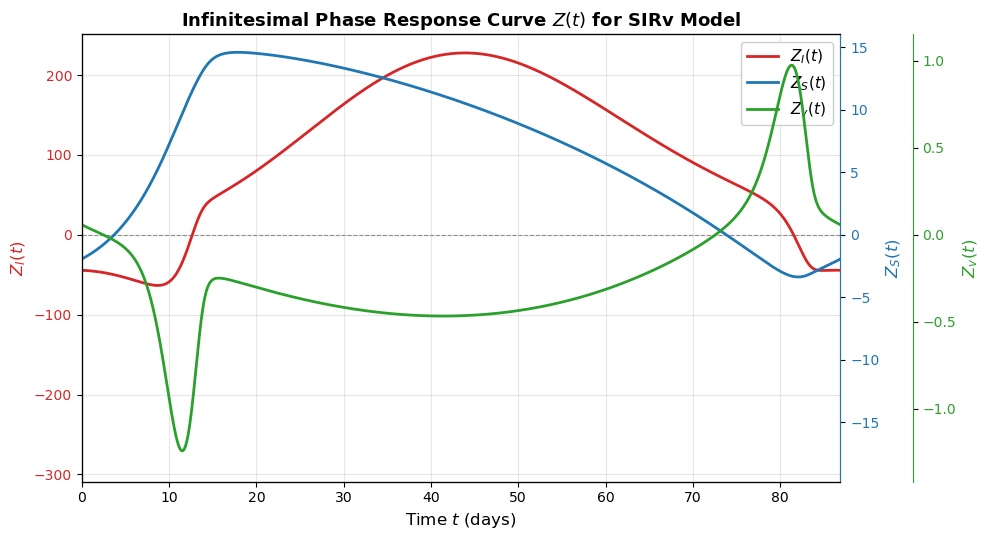


wrote iprc_three_axes.png


In [2]:
"""
Figure: infinitesimal phase response curve Z(t) for the SIRv model,
plotted on three vertical axes so that Z_S and Z_v are legible alongside Z_I.

Self-contained: finds the limit cycle, builds the Jacobian, solves the adjoint
equation, normalizes Z . gamma' = 2*pi/T, and plots.
"""

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.interpolate import interp1d


# =============================================================================
# SETTINGS
# =============================================================================

params = {
    'alpha': 0.01,
    'beta': 0.5,
    'gamma': 1/7,
    'eta': 1/7,
    'theta': 0.01,
    'kappa': 300,
    'rho': 0.01,
}

y0 = [0.49, 0.01, 0.01]

n_points = 100000      # resolution of one cycle
n_periods = 50         # periods of backward adjoint integration
OUTFILE = 'iprc_three_axes.png'


# =============================================================================
# SYSTEM
# =============================================================================

def uncoupled_smooth_sirv(t, y, params):
    """Uncoupled smooth SIRv system (epsilon = 0). y = [S, I, v]"""
    S, I, v = y
    alpha = params['alpha']
    beta = params['beta']
    gamma = params['gamma']
    eta = params['eta']
    theta = params['theta']
    kappa = params['kappa']
    rho = params['rho']

    dS = alpha*(1 - S - I) - beta*S*I - eta*v*S
    dI = -gamma*I + beta*S*I
    dv = -v + 1/(1 + np.exp(-kappa*(beta*I - rho - theta*(1 - 2*v))))

    return [dS, dI, dv]


# =============================================================================
# STEP 1: INTEGRATE PAST TRANSIENTS
# =============================================================================

sol_transient = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, 5000], y0, method='LSODA', rtol=1e-12, atol=1e-12
)
y_after_transient = sol_transient.y[:, -1]


# =============================================================================
# STEP 2: FIND THE PERIOD
# =============================================================================

dt = 0.01
t_eval = np.arange(0, 2000, dt)

sol_search = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, 2000], y_after_transient, method='LSODA',
    t_eval=t_eval, rtol=1e-12, atol=1e-12
)

I_data = sol_search.y[1, :]
peaks, _ = find_peaks(I_data, height=np.mean(I_data), distance=int(1/dt))
T = np.mean(np.diff(sol_search.t[peaks])[-5:])

print(f"Period T = {T:.6f} days")


# =============================================================================
# STEP 3: EXTRACT ONE COMPLETE CYCLE
# =============================================================================

y_cycle_start = sol_search.y[:, peaks[-2]]
t_cycle = np.linspace(0, T, n_points)

sol_cycle = solve_ivp(
    lambda t, y: uncoupled_smooth_sirv(t, y, params),
    [0, T], y_cycle_start, method='LSODA',
    t_eval=t_cycle, rtol=1e-12, atol=1e-14
)


class Gamma:
    """Limit cycle gamma(t) = [S(t), I(t), v(t)]"""
    t = sol_cycle.t
    S = sol_cycle.y[0, :]
    I = sol_cycle.y[1, :]
    v = sol_cycle.y[2, :]
    T = T
    y = sol_cycle.y


# =============================================================================
# STEP 4: JACOBIAN DF VIA SYMPY, EVALUATED ALONG THE CYCLE
# =============================================================================

S_sym, I_sym, v_sym = sp.symbols('S I v')
alpha_sym, beta_sym, gamma_sym, eta_sym = sp.symbols('alpha beta gamma eta')
theta_sym, kappa_sym, rho_sym = sp.symbols('theta kappa rho')

F = sp.Matrix([
    alpha_sym*(1 - S_sym - I_sym) - beta_sym*S_sym*I_sym - eta_sym*v_sym*S_sym,
    -gamma_sym*I_sym + beta_sym*S_sym*I_sym,
    -v_sym + 1/(1 + sp.exp(-kappa_sym*(beta_sym*I_sym - rho_sym
                                       - theta_sym*(1 - 2*v_sym))))
])

DF_func = sp.lambdify(
    (S_sym, I_sym, v_sym, alpha_sym, beta_sym, gamma_sym,
     eta_sym, theta_sym, kappa_sym, rho_sym),
    F.jacobian(sp.Matrix([S_sym, I_sym, v_sym])), modules='numpy'
)

A = np.zeros((n_points, 3, 3))
for i in range(n_points):
    A[i] = np.array(DF_func(
        Gamma.S[i], Gamma.I[i], Gamma.v[i],
        params['alpha'], params['beta'], params['gamma'],
        params['eta'], params['theta'], params['kappa'], params['rho']
    ))


# =============================================================================
# STEP 5: gamma'(t) ALONG THE CYCLE
# =============================================================================

Gamma_dot = np.zeros((3, n_points))
for i in range(n_points):
    Gamma_dot[:, i] = uncoupled_smooth_sirv(Gamma.t[i], Gamma.y[:, i], params)

Gamma.S_dot = Gamma_dot[0, :]
Gamma.I_dot = Gamma_dot[1, :]
Gamma.v_dot = Gamma_dot[2, :]


# =============================================================================
# STEP 6: SOLVE THE ADJOINT EQUATION BACKWARD
# =============================================================================

A_interp_base = interp1d(Gamma.t, A, axis=0, kind='linear',
                         fill_value='extrapolate')


def A_interp_periodic(t):
    return A_interp_base(np.mod(t, Gamma.T))


def adjoint_equation_reversed_periodic(s, Z, T):
    """Time-reversed adjoint equation: dZ/ds = A(T - s mod T)^T @ Z"""
    return A_interp_periodic(T - (s % T)).T @ Z


total_time = n_periods * Gamma.T
n_points_total = n_points * n_periods
s_eval = np.linspace(0, total_time, n_points_total)

print(f"Integrating adjoint for {n_periods} periods ({total_time:.1f} days)")

sol_adjoint = solve_ivp(
    lambda s, Z: adjoint_equation_reversed_periodic(s, Z, Gamma.T),
    [0, total_time], np.array([1.0, 1.0, 1.0]), method='RK45',
    t_eval=s_eval, rtol=1e-10, atol=1e-12
)

Z_raw = sol_adjoint.y[:, (n_periods - 1)*n_points:][:, ::-1]

if Z_raw.shape[1] != n_points:
    t_raw = np.linspace(0, Gamma.T, Z_raw.shape[1])
    Z_raw = np.vstack([np.interp(Gamma.t, t_raw, Z_raw[i, :]) for i in range(3)])


# =============================================================================
# STEP 7: NORMALIZE SO THAT Z . gamma' = 2*pi/T
# =============================================================================

omega = 2 * np.pi / Gamma.T
Z_dot_Gamma_dot = np.sum(Z_raw * Gamma_dot, axis=0)
Z_normalized = Z_raw * omega / Z_dot_Gamma_dot

check = np.sum(Z_normalized * Gamma_dot, axis=0)
print(f"omega = 2*pi/T = {omega:.6f}")
print(f"Z . gamma' after normalization: "
      f"{check.min():.6f} to {check.max():.6f}")


class Z_solution:
    """iPRC Z(t) = [Z_S(t), Z_I(t), Z_v(t)]"""
    t = Gamma.t
    S = Z_normalized[0, :]
    I = Z_normalized[1, :]
    v = Z_normalized[2, :]
    y = Z_normalized
    T = Gamma.T


Z = Z_solution()

print(f"Z_S range: [{Z.S.min():.4f}, {Z.S.max():.4f}]")
print(f"Z_I range: [{Z.I.min():.4f}, {Z.I.max():.4f}]")
print(f"Z_v range: [{Z.v.min():.4f}, {Z.v.max():.4f}]")


# =============================================================================
# STEP 8: PLOT ON THREE VERTICAL AXES
# =============================================================================

def align_zeros(pairs, pad=0.08):
    """Set y-limits so that y = 0 sits at the same height on every axis."""
    lims = []
    for ax, dat in pairs:
        m, M = float(np.min(dat)), float(np.max(dat))
        s = (M - m)*pad
        lims.append([m - s, M + s])
    f = max(-lo/(hi - lo) for lo, hi in lims)
    for (ax, _), (lo, hi) in zip(pairs, lims):
        ax.set_ylim(-f/(1 - f)*hi, hi)


fig, axL = plt.subplots(figsize=(10, 5.5))
axR1 = axL.twinx()
axR2 = axL.twinx()
axR2.spines['right'].set_position(('outward', 52))

l1, = axL.plot(Z.t, Z.I, color='#d62728', lw=2, label='$Z_I(t)$')
l2, = axR1.plot(Z.t, Z.S, color='#1f77b4', lw=2, label='$Z_S(t)$')
l3, = axR2.plot(Z.t, Z.v, color='#2ca02c', lw=2, label='$Z_v(t)$')

align_zeros([(axL, Z.I), (axR1, Z.S), (axR2, Z.v)])
axL.axhline(0, color='0.5', lw=0.8, ls='--', zorder=0)

for ax, c, lab in ((axL, '#d62728', '$Z_I(t)$'),
                   (axR1, '#1f77b4', '$Z_S(t)$'),
                   (axR2, '#2ca02c', '$Z_v(t)$')):
    ax.set_ylabel(lab, fontsize=12, color=c)
    ax.tick_params(axis='y', labelcolor=c)
    ax.spines['right'].set_color(c)

axL.set_xlabel('Time $t$ (days)', fontsize=12)
axL.set_xlim(Z.t[0], Z.t[-1])
axL.grid(True, alpha=0.3)
axL.set_title('Infinitesimal Phase Response Curve $Z(t)$ for SIRv Model',
              fontsize=13, fontweight='bold')
axL.legend(handles=[l1, l2, l3], loc='upper right', fontsize=11,
           framealpha=0.95)

plt.tight_layout()
plt.savefig(OUTFILE, dpi=150, bbox_inches='tight')
plt.show()

print(f"\nwrote {OUTFILE}")